In [14]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import os,csv,re

* 进入文件路径

In [2]:
os.getcwd()
#os.chdir(r'data_analysis\FZU')

'e:\\projects\\collection-ai\\foundation\\hyzzz145\\task-2\\data_analysis\\FZU'

* 抓取通知人个数

In [ ]:
notice_people = pd.Series({})
with open('data_file/content.csv','r',encoding='utf-8') as f:
    for lines in f:
        if '通知人：' in lines:
            people = lines.replace('通知人：','').strip()
            if people in notice_people.keys():
                notice_people[people] += 1
            else:
                notice_people[people] = 1

* 抓取课程调整类通知

In [ ]:
with open('data_file/content.csv','r',encoding='utf-8',newline='') as f:
    with open('data_file/course_adjust.csv','w',encoding='utf-8',newline='') as g:
        writer = csv.writer(g)
        #history 用于查找保存
        history = []
        collection = False
        idx = 0
        print('准备遍历csv')
        for lines in f:
            lines = lines.strip()
            history.append(lines)
            if not collection and len(history)>2:
                history.pop(1)
            if '课程调整' in lines:
                idx += 1
                print(f'查询到第{idx}个‘课程调整’')
                collection = True
            if lines.strip() == '' and collection:
                history.pop(-1)
                writer.writerow([f'-------------第{idx}个课程调整----------'])
                writer.writerows([[i] for i in history])
                writer.writerow([' '])
                print(f'已写入第{idx}个‘课程调整’')
                history.clear()
                collection = False

print('over')
    
       

            
        

* 分析通知人和附件下载次数的关系

In [ ]:
#通知数
notice_num = 0
#行数
line_num = 0
#遍历读取csv
history_2 = []
is_collect = False
#下载数量列表
download = []
#构造通知人——下载关系字典
notice_download = pd.DataFrame({},columns=['通知人','附件数','总下载数','平均下载数'])
#平均下载转小数
notice_download['平均下载数'] = notice_download['平均下载数'].astype(float)
#设置新索引
notice_download.set_index('通知人',inplace=True)
#打开并读取福大csv内容
with open('data_file/content.csv','r',encoding='utf-8') as f:
    #遍历每行
    print('开始遍历福大通知每行')
    for lines in f:
        #行数加一
        line_num += 1
        #暂时加入history缓存（遵从一个文章一个文章的保存，并在后面进行处理）
        history_2.append(lines)
        #检测此文是否带有附件
        if not is_collect and '附件名' in lines:
            print(f'第{line_num}行存在附件名')
            is_collect = True
        #检测文章是否结束
        if lines.strip() == '':
            download = []
            #第几个通知
            notice_num += 1
            print(f'第{line_num}行检测第{notice_num}个通知截止')
            #如果存在附件，进行一些操作进行修改字典
            if is_collect:
                #寻找通知人
                for i in history_2:
                    if '通知人' in i:
                        #通知人
                        notice_people2 = i.replace('通知人：','').strip()
                        print(f'通知人：{notice_people2}')
                    #寻找下载数据
                    elif '已下载' in i:
                        download.append(int(i.replace('已下载','').replace('次','')))
                        print(f'下载数列表：{download}')       
                len_down = len(download)
                sum_down = sum(download_num for download_num in download)
                average_down = round(sum_down/len_down,2)
                #如果 df 已经存在此通知人
                if notice_people2 in notice_download.index:
                    print(f'存在{notice_people2}通知人于df')
                    notice_download.loc[notice_people2,'附件数'] += len_down
                    notice_download.loc[notice_people2,'总下载数'] += sum_down
                    notice_download.loc[notice_people2,'平均下载数'] = average_down
                    print(f'附件数：{notice_download.loc[notice_people2,'附件数']}\n总下载数：{notice_download.loc[notice_people2,'总下载数']}\n平均下载数：{notice_download.loc[notice_people2,'平均下载数']}')
                #若不存在
                else:
                    print(f'不存在{notice_people2}通知人于df')
                    notice_download.loc[notice_people2] = [len_down,sum_down,average_down]
                    print(f'附件数：{len_down}\n总下载数：{sum_down}\n平均下载数：{average_down}')              
                is_collect = False
            #清空
            history_2.clear()
#打开要写入的通知人文件
print(notice_download)
notice_download[['附件数','总下载数']] = (
    notice_download[['附件数','总下载数']].astype(int)
)
notice_download.to_csv('data_file/notice_download.csv',encoding='utf-8')
print('over')

            
            


- 分析发布高峰期，统计每天发布数量，那个学期时段，通知最多

In [ ]:
# 思路：首先创建一个 df ，以日期为 index ，colums 包括 【通知数】
#初始化
history_3 = []
notice_num = 0
time_notice_df = pd.DataFrame(columns=["通知数"])
with open('data_file/content.csv','r',encoding='utf-8') as f:
    for lines in f:
        if '发布时间' in lines:
            notice_num += 1
            print(f"第{notice_num}份通知")
            time = lines.replace('发布时间：','').strip()
            if not time in time_notice_df.index:
                time_notice_df.loc[time] = [1]
            else:
                time_notice_df.loc[time] += 1
# 学期时段与通知数的关系
period_notice = pd.DataFrame(0,
    index=['假期','开学','期中','后半学期','期末']
    ,columns=["通知数"]
    )
for time in time_notice_df.index:
    print(time)
    sum_ = time_notice_df.loc[time,'通知数']
    month = int(re.search(r'\d{4}-(\d{1,2})-\d{1,2}',time).group(1))
    print(f'月份：{month}')
    if (month >= 2 and month < 3) or (month >= 7 and month < 9):
        period_notice.loc['假期'] += sum_
    elif (month == 3 or month == 9):
        period_notice.loc['开学'] += sum_
    elif (month == 4 or month == 10 or month == 11 ):
        period_notice.loc['期中'] += sum_
    elif (month == 5 or month == 12):
        period_notice.loc['后半学期'] += sum_
    else:  
        period_notice.loc['期末'] += sum_

time_notice_df.to_csv('data_file/time_notice.csv')
period_notice.to_csv('data_file/time_notice.csv',mode='a')
df_max = period_notice['通知数'].idxmax()
print('通知数最多的时段')
print(df_max)
print(period_notice.loc[df_max])





# There is relied on my free 


- This is relationship of keyword in accompanying materials and the number of downloads(不是复制ai的哈，只是想试试用英语写注释)

In [ ]:
''' My idea : firstly,I create a list to restore my key word
Then I create a dataframe whose index is kekword and columns
are *total number of downloads* and *number of accompanying
materials* and *average number of download* 
'''
#some init
is_record = False
#history to store single accompany material
history_4 = []
# keyword list
keyword_list = ['申报书','意见','课程清单','评分表','使用手册','审批表','期末','期中','名单']
#df 
keyword_download_df = pd.DataFrame(
    0,
    index=keyword_list,
    columns=['下载总量','材料数','下载平均数']
    )
#float 
keyword_download_df['下载平均数'] = keyword_download_df['下载平均数'].astype(float)
#iterate through the content.csv
with open('data_file/content.csv','r',encoding='utf-8') as f:
    for lines in f:
        if '附件名' in lines:
            is_record = True
            print('已寻找到附件')
        if is_record:
            history_4.append(lines)
        if is_record and '已下载' in lines:
            is_record = False
            #analyse 
            download = int(lines.replace('已下载','').replace('次',''))
            for keyword in keyword_download_df.index:
                if keyword in history_4[0]:
                    print(f'在此附件中寻找到‘{keyword}’关键词')
                    print(f'下载数{download}')
                    keyword_download_df.loc[keyword,'下载总量'] += download
                    keyword_download_df.loc[keyword,'材料数'] += 1
            history_4.clear()
#caculate average 
for keyword in keyword_download_df.index:
    if keyword_download_df.loc[keyword,'材料数'] != 0:
        keyword_download_df.loc[keyword,'下载平均数'] = round(keyword_download_df.loc[keyword,'下载总量'] / keyword_download_df.loc[keyword,'材料数'],2)
        print(f'已计算了{keyword}的平均下载数')
    else:
        print(f"{keyword}材料总数等于0")
with open('data_file/keyword_download.csv','w',encoding='utf-8',newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['附件关键词与下载数的关系'])
keyword_download_df.to_csv('data_file/keyword_download.csv',mode='a')
#find max_download keyword
max_keyword = keyword_download_df['下载平均数'].idxmax()
with open('data_file/keyword_download.csv','a',encoding='utf-8',newline='') as f:
    writer = csv.writer(f)
    writer.writerow([f'--------最大平均下载量的关键词是[{keyword}]-----------'])
print('over')

- matplotlib课程调整

In [ ]:
#对调整课程分析(调课时间)
dic = {}
with open('data_file/course_adjust.csv','r',encoding='utf-8') as f:
    for lines in f:
        if '发布时间' in lines:
            print('ok')
            time = lines.replace('发布时间：','')
            time = re.search(r'(\d{4})-\d{2}-\d{2}',time).group(1)
            print(time)
            if time in dic.keys():
                dic[time] += 1
            else:
                dic[time] = 0
    print('调课分析完成')
# 让dic倒过来
dic = dict(reversed(list(dic.items())))

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
plt.figure(dpi=260)
plt.title('调课次数与年份关系',fontsize=16)
fig_1 = plt.plot(dic.keys(),dic.values())
plt.show()


- matplotlib 发布让和下载量的关系

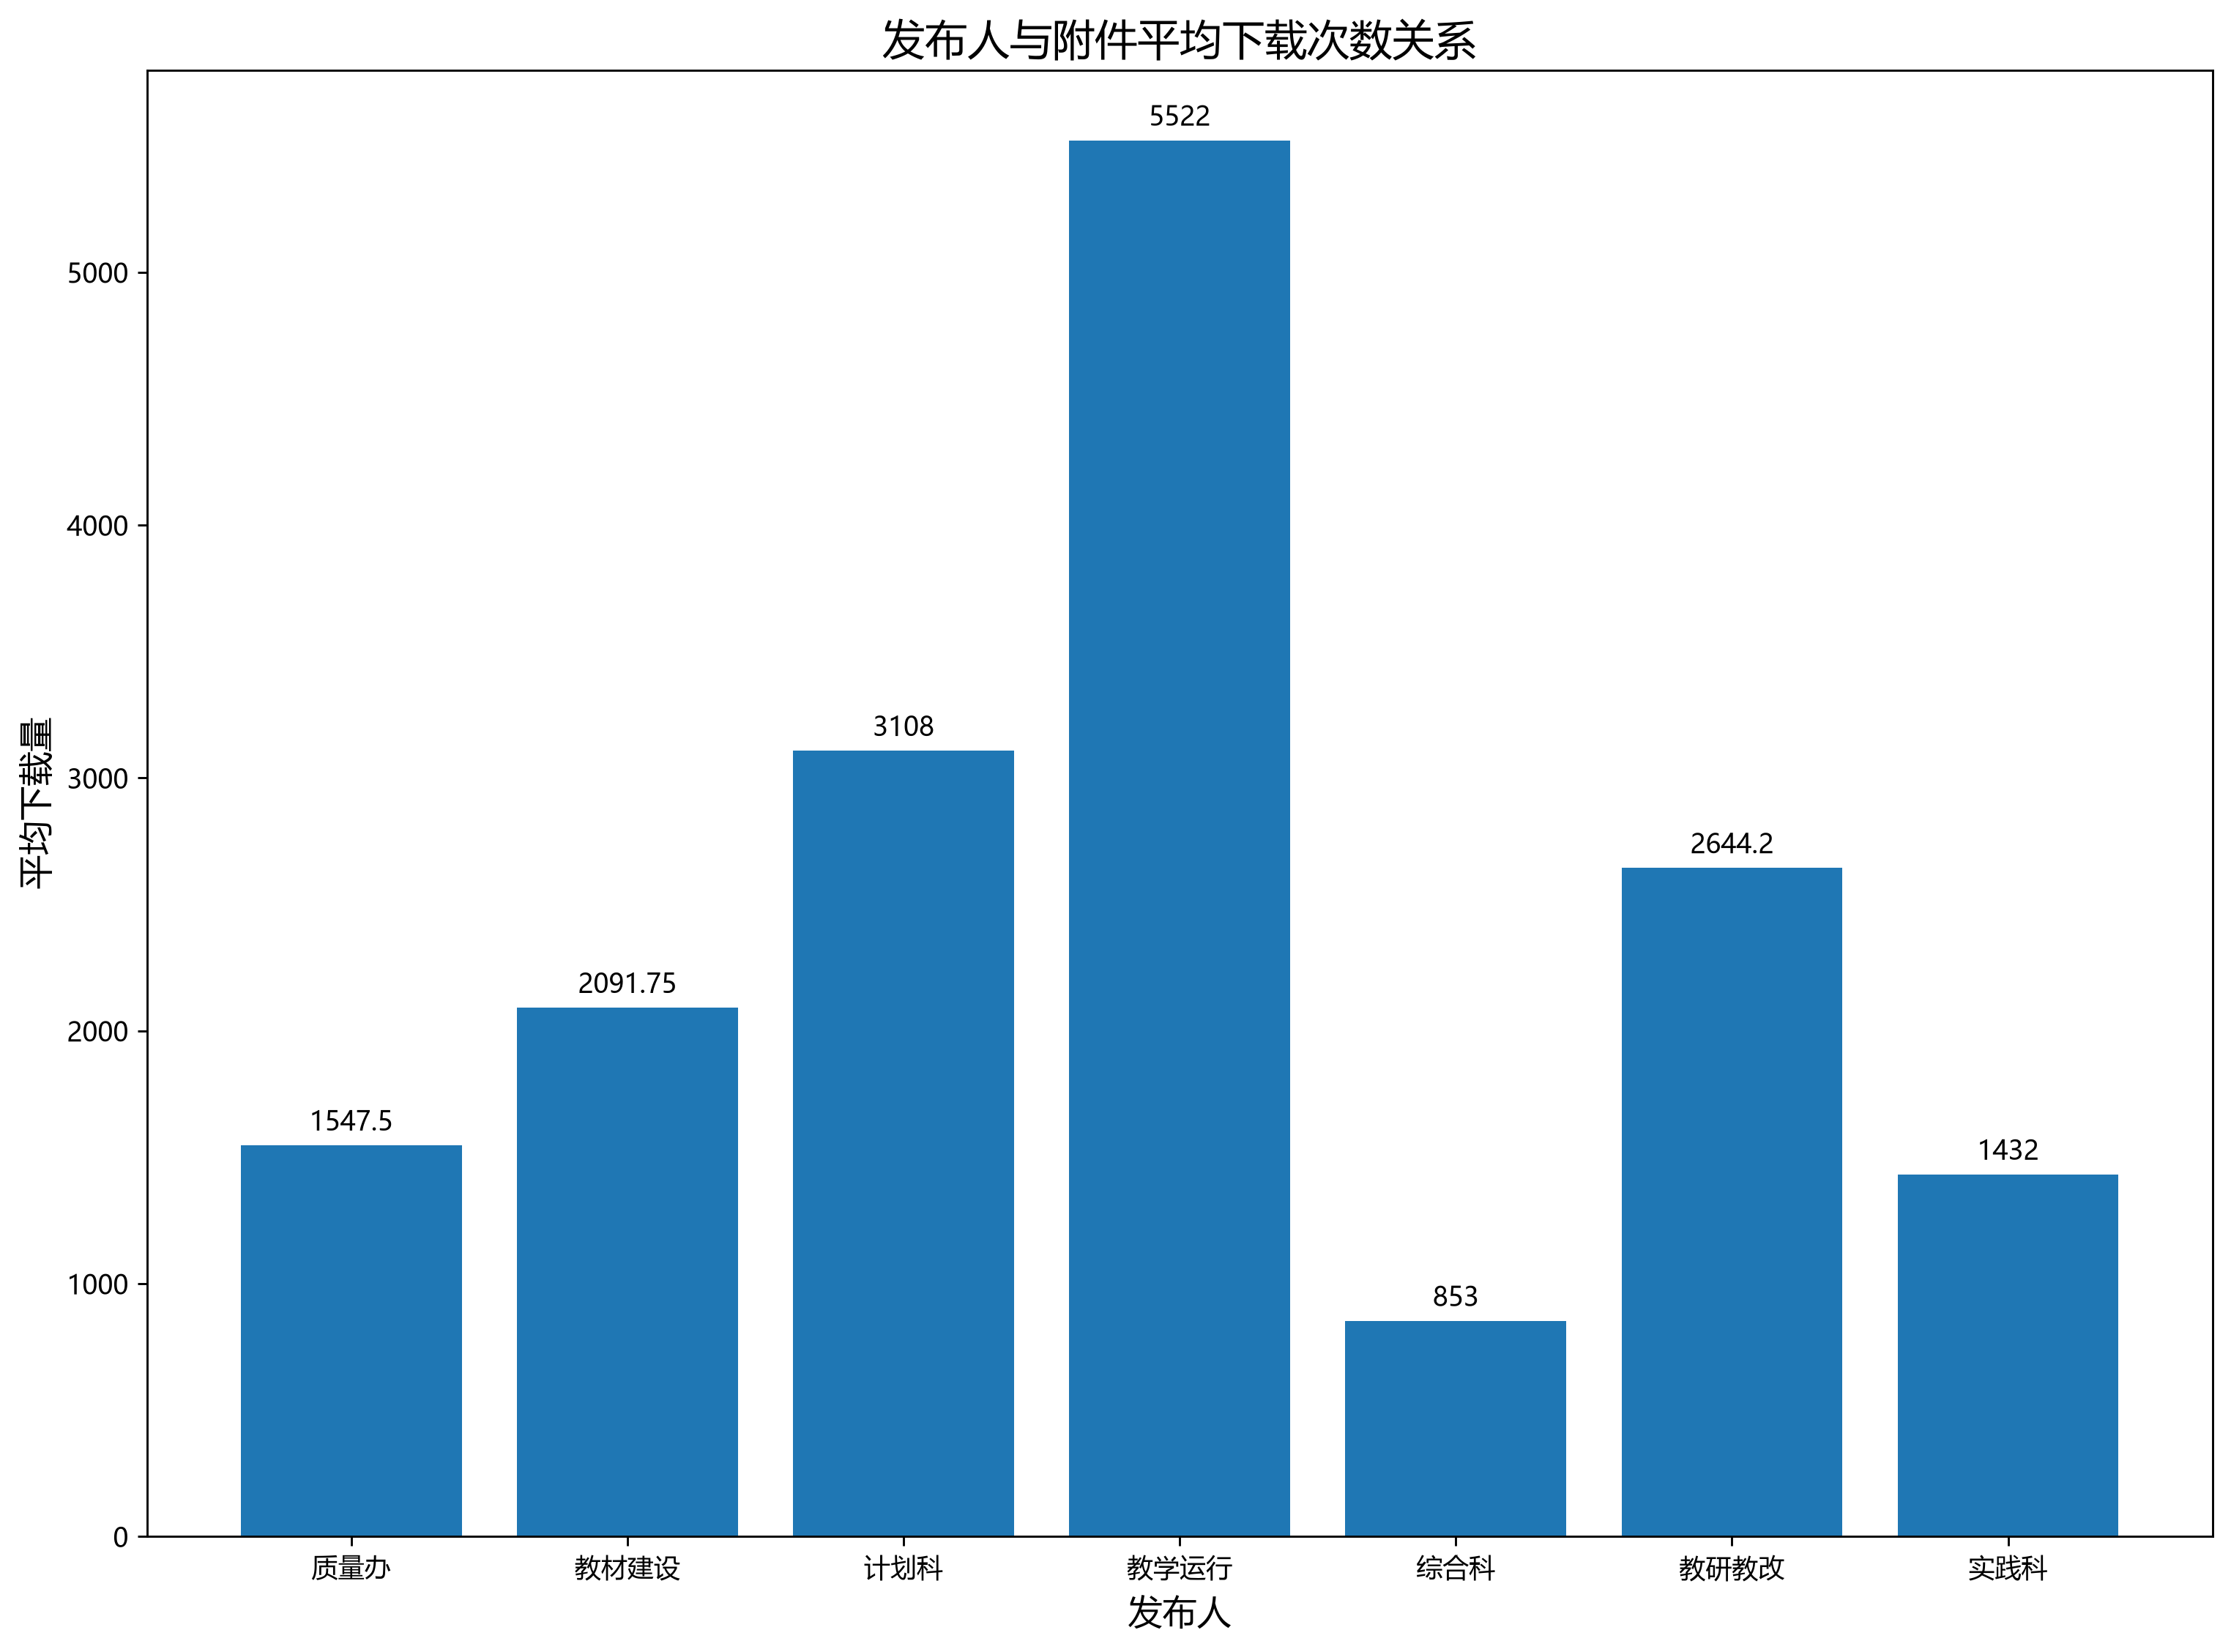

In [43]:
df = pd.read_csv(r'data_file\notice_download.csv',encoding='utf-8')
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
plt.figure(figsize=(14,10),dpi=260)
plt.title('发布人与附件平均下载次数关系',fontsize = 16)
plt.xlabel('发布人',fontsize = 13)
plt.ylabel('平均下载量',fontsize = 13)
fig_2 = plt.bar(df['通知人'],df['平均下载数'])
plt.bar_label(fig_2, padding=3)
plt.show()



In [ ]:
print(notice_people)